# Phát triển Mạng Nơ-ron PyTorch MLP (`ReLU` vs `SiLU`) & Đối sánh Toàn diện 5 Mô hình
**Dự án:** Hệ thống Nhận diện Ý định Hội thoại NPC trong Game Nhập vai (Vietnamese RPG Intent Classification)  
**Kiến trúc Mạng Nơ-ron:** `Input (2000)` $\rightarrow$ `Linear(512) + Act + Dropout(0.5)` $\rightarrow$ `Linear(128) + Act + Dropout(0.5)` $\rightarrow$ `Linear(5)`

---

### Mục tiêu của Notebook
1. **Độc lập hoàn toàn (Self-Contained)**: Nhúng trực tiếp lớp mạng `NeuralNetwork` của dự án và bộ cấp phát dữ liệu/mô hình 3 tầng (Local Repo $\rightarrow$ GitHub Raw $\rightarrow$ Offline Auto-Generate) để chạy trơn tru dù chỉ tải riêng lẻ 1 file `.ipynb`.
2. **Phân tích toán học & Thực nghiệm hàm kích hoạt (`ReLU` vs `SiLU`)**: Trực quan hóa đặc tính đạo hàm, huấn luyện mạng nơ-ron đa tầng PyTorch và vẽ đường cong hội tụ (*Loss*, *Accuracy*, *Macro F1*) qua các Epoch.
3. **Đối sánh Toàn diện 5 Mô hình (*Comprehensive Benchmark*)**: Đặt 2 biến thể `PyTorch MLP (ReLU, SiLU)` lên bàn cân cùng 3 mô hình Học máy kinh điển (`Multinomial NB`, `Linear SVM`, `Logistic Regression`) về Độ chính xác, Macro F1, Độ trễ mili-giây và Dung lượng lưu trữ.
4. **Phân tích lỗi sai (*Error Analysis*)**: Khảo sát các câu *Hard Negatives* gây nhầm lẫn điển hình trên tập kiểm thử 2.000 mẫu.

## 0. Khởi tạo Môi trường, Định nghĩa `NeuralNetwork` & Cấp phát Tài nguyên 3 Tầng
Ô khởi tạo dưới đây tích hợp sẵn bản vá lỗi tương thích `packaging.version` của `PyTorch` trên Python 3.13 / Windows, định nghĩa kiến trúc `NeuralNetwork` giống hệt `network/neural_network.py`, và tự động chuẩn bị ma trận `TF-IDF` cùng các mô hình cơ sở để đối sánh.

In [1]:
import copy
import importlib.util
import json
import os
import pickle
import subprocess
import sys
import time
import urllib.request
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

REQUIRED_PACKAGES = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn", "torch": "torch", "matplotlib": "matplotlib"}
missing_pkgs = [pip_name for mod, pip_name in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing_pkgs:
    print(f"[Setup] Đang cài đặt gói thư viện thiếu: {missing_pkgs} ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_pkgs])

try:
    import packaging.version
    sys.modules.setdefault("torch._vendor.packaging.version", packaging.version)
except Exception:
    pass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Segoe UI", "Arial"]
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

INTENT_NAMES = ["GREETING", "TRADE", "INFO", "HOSTILE", "UNKNOWN"]
INTENT_TO_ID = {name: i for i, name in enumerate(INTENT_NAMES)}
ID_TO_INTENT = {i: name for i, name in enumerate(INTENT_NAMES)}
GITHUB_RAW_BASE = "https://raw.githubusercontent.com/DianLiberos/intent-classification/main"
OVERWRITE_PROJECT_WEIGHTS = False  # Giữ False để bảo toàn file ReLU.pth / SiLU.pth gốc của dự án

class NeuralNetwork(nn.Module):
    """Kiến trúc PyTorch MLP chuẩn của dự án: 2000 -> 512 -> Act -> Dropout(0.5) -> 128 -> Act -> Dropout(0.5) -> 5"""
    def __init__(self, activation_function: str = "ReLU", dropout_p: float = 0.5):
        super().__init__()
        if activation_function == "ReLU":
            act = nn.ReLU
        elif activation_function == "SiLU":
            act = nn.SiLU
        else:
            raise ValueError(f"Unsupported activation_function: {activation_function}")

        self.sequential_stack = nn.Sequential(
            nn.Linear(2000, 512),
            act(),
            nn.Dropout(dropout_p),
            nn.Linear(512, 128),
            act(),
            nn.Dropout(dropout_p),
            nn.Linear(128, 5),
        )

    def forward(self, x):
        return self.sequential_stack(x)


def _synthesize_offline_rpg_dataset(data_dir: Path, n_train_seeds: int = 80, n_test_seeds: int = 30):
    """Tier 3 Fallback: Sinh bộ dữ liệu RPG tiếng Việt chuẩn Zero-Leakage khi chạy lẻ hoàn toàn Offline."""
    import random, re, unicodedata, csv
    rng = random.Random(42)
    data_dir.mkdir(parents=True, exist_ok=True)

    vocab = {
        "pronoun": ["tôi", "tui", "mình", "em", "anh", "tại hạ", "kẻ lữ hành này", "tao"],
        "npc": ["ông chủ", "chủ tiệm", "shop", "lão bản", "thợ rèn", "thương nhân", "trưởng làng", "tiền bối"],
        "greet": ["xin chào", "chào", "hello", "hi", "alo", "kính chào", "bái kiến", "hú"],
        "item": ["kiếm sắt", "đại đao", "cung gỗ", "giáp sắt", "bình máu", "bình mana", "đá cường hóa", "quặng sắt", "vảy rồng"],
        "currency": ["vàng", "bạc", "xu", "kim cương", "gold", "linh thạch"],
        "buy": ["mua", "lấy", "tậu", "chốt", "sắm", "đổi lấy"],
        "loc": ["rừng phía bắc", "hang nhện", "đầm lầy tử thần", "làng tân thủ", "tháp ma thuật", "hầm ngục tối"],
        "monster": ["goblin", "slime", "rồng lửa", "quỷ vương", "sói xám", "nhện độc"],
        "quest": ["nhiệm vụ", "quest", "ủy thác", "bản đồ kho báu", "mật thư"],
        "insult": ["đồ phế vật", "thằng lừa đảo", "đồ ăn hại", "lão già dịch", "đồ hút máu"],
        "hostile": ["đập nát tiệm", "đốt quán", "chém chết", "cướp sạch", "san phẳng chỗ này"],
        "ood": ["bitcoin", "trà sữa trân châu", "code Python", "iPhone 16", "giá xăng hôm nay", "Ngoại hạng Anh", "mật khẩu wifi"],
    }

    train_tpl = {
        "GREETING": [
            "{greet} {npc}, chúc một ngày tốt lành!",
            "{npc} ơi, {pronoun} mới tới vùng này, {greet} nhé!",
            "Lâu quá không gặp {npc}, dạo này vẫn khỏe chứ?",
            "{greet} {npc}, {pronoun} vừa đi săn ở {loc} về ghé chào một tiếng!",
        ],
        "TRADE": [
            "{npc} ơi, bán cho {pronoun} một cái {item} tính bằng {currency} với.",
            "Món {item} này giá bao nhiêu {currency} vậy {npc}?",
            "{pronoun} muốn {buy} ít {item}, mở kho hàng xem thử nào!",
            "Giảm giá món {item} chút đi {npc}, {pronoun} {buy} liền trả đủ {currency}!",
        ],
        "INFO": [
            "{npc} cho {pronoun} hỏi đường đi tới {loc} ở hướng nào vậy?",
            "Làm sao để hạ gục con {monster} ở {loc} thế {npc}?",
            "Ở đây có {quest} nào mới cho {pronoun} nhận không {npc}?",
            "Đánh con {monster} ở {loc} thì rớt nguyên liệu {item} nào vậy?",
        ],
        "HOSTILE": [
            "Đồ {insult}, hôm nay {pronoun} sẽ {hostile} của mày!",
            "Bán {item} giá cắt cổ thế à, định cướp cạn hả {insult}?",
            "Cút ngay trước khi tao nổi điên tới {hostile} đồ {insult}!",
            "Nhìn mặt {npc} ngứa mắt thật sự, bước ra đây solo đi {insult}!",
        ],
        "UNKNOWN": [
            "{npc} ơi, hôm nay giá {ood} ngoài đời là bao nhiêu tiền vậy?",
            "Chỉ giúp {pronoun} cách học {ood} sao cho nhanh giỏi với!",
            "Quanh đây có quán nào bán {ood} giao tận nhà không nhỉ?",
            "Đổi 1000 {currency} trong game lấy {ood} ngoài đời thật được không shop?",
        ],
    }

    test_tpl = {
        "GREETING": [
            "Ồ {npc} vẫn canh tiệm đấy à, {greet} buổi sáng nha!",
            "Một ngày bình an nhé {npc}, {pronoun} ghé qua điểm danh cái!",
        ],
        "TRADE": [
            "Thanh toán cho {pronoun} món {item} bằng {currency} lẹ đi {npc}!",
            "Có nhận trao đổi {item} cũ bù thêm {currency} lấy đồ mới không shop?",
        ],
        "INFO": [
            "Bí kíp nào vượt ải {loc} mà không bị {monster} đánh bại vậy {npc}?",
            "Ai là người giao {quest} thám hiểm vùng {loc} hả {npc}?",
        ],
        "HOSTILE": [
            "Tiệm rách nát bán toàn {item} dỏm, dẹp tiệm đi đồ {insult}!",
            "Nói thêm câu nữa là tao {hostile} ngay tại chỗ đấy {insult}!",
        ],
        "UNKNOWN": [
            "Tư vấn giùm {pronoun} có nên đầu tư vào {ood} năm nay không?",
            "Ngoài đời đang bận {ood} mà tự nhiên vô game hỏi {npc} làm chi không biết!",
        ],
    }

    def strip_accents(s: str) -> str:
        s = re.sub(r"[đ]", "d", re.sub(r"[Đ]", "D", s))
        return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")

    def to_teencode(s: str) -> str:
        out = s.lower()
        subs = [(r"\bkhông\b", "ko"), (r"\bbao nhiêu\b", "bn"), (r"\bông chủ\b", "shop"),
                (r"\btôi\b", "tui"), (r"\bvậy\b", "z"), (r"\bvới\b", "vs"), (r"\bđược\b", "dc")]
        for pat, rep in subs:
            if rng.random() < 0.75:
                out = re.sub(pat, rep, out)
        return re.sub(r"[!?.]+$", "", out).strip()

    def fill(tpl: str) -> str:
        out = tpl
        for k in re.findall(r"\{(\w+)\}", tpl):
            out = out.replace(f"{{{k}}}", rng.choice(vocab[k]), 1)
        return out

    def make_split(tpl_map, seeds_per_intent, seen_norm):
        rows = []
        for intent, tpls in tpl_map.items():
            cnt, tries = 0, 0
            while cnt < seeds_per_intent and tries < seeds_per_intent * 40:
                tries += 1
                seed = fill(rng.choice(tpls))
                key = strip_accents(seed.lower())
                if key in seen_norm:
                    continue
                seen_norm.add(key)
                cnt += 1
                v1 = seed
                v2 = to_teencode(seed)
                v3 = strip_accents(v2)
                v4 = f"ê {v2} nha"
                for v in (v1, v2, v3, v4):
                    rows.append({"text": v, "intent": intent})
        rng.shuffle(rows)
        return rows

    seen = set()
    train_rows = make_split(train_tpl, n_train_seeds, seen)
    test_rows = make_split(test_tpl, n_test_seeds, seen)
    full_rows = train_rows + test_rows

    (data_dir / "train.json").write_text(json.dumps(train_rows, ensure_ascii=False, indent=2), encoding="utf-8")
    (data_dir / "test.json").write_text(json.dumps(test_rows, ensure_ascii=False, indent=2), encoding="utf-8")
    (data_dir / "dataset_full.json").write_text(json.dumps(full_rows, ensure_ascii=False, indent=2), encoding="utf-8")

    intents_list = list(train_tpl.keys())
    with open(data_dir / "dataset_ver1.csv", "w", encoding="utf-8", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["id", "text", "annonator_1", "annonator_2", "final intent"])
        for idx, row in enumerate(train_rows[:200], start=1):
            a1 = row["intent"]
            a2 = a1 if rng.random() > 0.08 else rng.choice(intents_list)
            writer.writerow([idx, row["text"], a1, a2, row["intent"]])

    return train_rows, test_rows


def resolve_dl_resources():
    force_standalone = os.environ.get("FORCE_STANDALONE_TEST", "0") == "1"
    force_offline = os.environ.get("FORCE_OFFLINE_FALLBACK", "0") == "1"

    if not force_standalone:
        cwd = Path.cwd().resolve()
        for root in [cwd, cwd.parent, cwd.parent.parent, cwd / "intent-classification"]:
            proc = root / "data" / "processed"
            if (proc / "X_train.npz").exists() and (proc / "X_test.npz").exists():
                out_dir = (root / "network" / "models") if OVERWRITE_PROJECT_WEIGHTS else (Path.cwd().resolve() / "artifacts_pytorch_mlp")
                out_dir.mkdir(parents=True, exist_ok=True)
                return root / "data", proc, root / "network" / "models", out_dir, f"Tầng 1 - Kho dự án cục bộ ({root})"

    ws = Path.cwd().resolve() / "standalone_workspace"
    ws_data, ws_proc, ws_models = ws / "data", ws / "processed", ws / "models"
    for d in (ws_data, ws_proc, ws_models):
        d.mkdir(parents=True, exist_ok=True)

    if not force_offline and not (ws_proc / "X_train.npz").exists():
        try:
            print("[Bootstrap] Đang tải dữ liệu & mô hình cơ sở từ GitHub...")
            files_to_fetch = [
                ("data/test.json", ws_data / "test.json"),
                ("data/processed/X_train.npz", ws_proc / "X_train.npz"),
                ("data/processed/X_test.npz", ws_proc / "X_test.npz"),
                ("data/processed/y_train.npy", ws_proc / "y_train.npy"),
                ("data/processed/y_test.npy", ws_proc / "y_test.npy"),
                ("data/processed/nb_model.pkl", ws_proc / "nb_model.pkl"),
                ("data/processed/svm_model.pkl", ws_proc / "svm_model.pkl"),
                ("data/processed/lr_model.pkl", ws_proc / "lr_model.pkl"),
            ]
            for rel_url, dst in files_to_fetch:
                req = urllib.request.Request(f"{GITHUB_RAW_BASE}/{rel_url}", headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(req, timeout=12) as resp:
                    dst.write_bytes(resp.read())
            return ws_data, ws_proc, ws_models, ws_models, f"Tầng 2 - Tải tự động từ GitHub ({ws})"
        except Exception as err:
            print(f"[Bootstrap] Không tải được từ GitHub ({err}). Chuyển sang Tầng 3 (Offline Auto-Build)...")

    if not (ws_proc / "X_train.npz").exists():
        train_rows, test_rows = _synthesize_offline_rpg_dataset(ws_data)
        vec = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), sublinear_tf=True)
        X_tr = vec.fit_transform([r["text"] for r in train_rows])
        X_te = vec.transform([r["text"] for r in test_rows])
        y_tr = np.array([INTENT_TO_ID[r["intent"]] for r in train_rows])
        y_te = np.array([INTENT_TO_ID[r["intent"]] for r in test_rows])
        sp.save_npz(ws_proc / "X_train.npz", X_tr)
        sp.save_npz(ws_proc / "X_test.npz", X_te)
        np.save(ws_proc / "y_train.npy", y_tr)
        np.save(ws_proc / "y_test.npy", y_te)
        with open(ws_proc / "tfidf_vectorizer.pkl", "wb") as f:
            pickle.dump(vec, f)

    return ws_data, ws_proc, ws_models, ws_models, f"Tầng 3 - Khởi tạo Độc lập ({ws})"


DATA_DIR, PROCESSED_DIR, EXISTING_NN_DIR, SAVE_NN_DIR, MODE_DESC = resolve_dl_resources()
print(f"✅ Chế độ tài nguyên : {MODE_DESC}")
print(f"🖥️ Thiết bị tính toán : {DEVICE.upper()} (PyTorch {torch.__version__})")

✅ Chế độ tài nguyên : Tầng 1 - Kho dự án cục bộ (D:\project may hoc\intent-classification)
🖥️ Thiết bị tính toán : CPU (PyTorch 2.8.0+cpu)


## 1. Cơ sở Lý thuyết: Đối sánh Hàm Kích hoạt `ReLU` và `SiLU (Swish)`
Trong kiến trúc mạng nơ-ron truyền thẳng 3 tầng tuyến tính của dự án (`2000 -> 512 -> 128 -> 5`), hai hàm kích hoạt phi tuyến được thử nghiệm là:
- **ReLU (*Rectified Linear Unit*)**:
  $$\text{ReLU}(x) = \max(0, x)$$
  Tính toán cực nhanh, không bão hòa miền dương nhưng có đạo hàm bằng $0$ tuyệt đối với mọi $x < 0$ (hiện tượng *Dying ReLU* với dữ liệu thưa).
- **SiLU (*Sigmoid Linear Unit* / *Swish*)**:
  $$\text{SiLU}(x) = x \cdot \sigma(x) = \frac{x}{1 + e^{-x}}$$
  Đường cong trơn khả vi mọi nơi và không đơn điệu nhẹ ở miền âm nhỏ ($x \approx -1.28$), cho phép dòng gradient nhỏ đi qua các nơ-ron âm.

Tổng số tham số có thể học của mỗi mạng PyTorch MLP (2000 -> 512 -> 128 -> 5): 1,090,821 tham số (~4.16 MB float32)


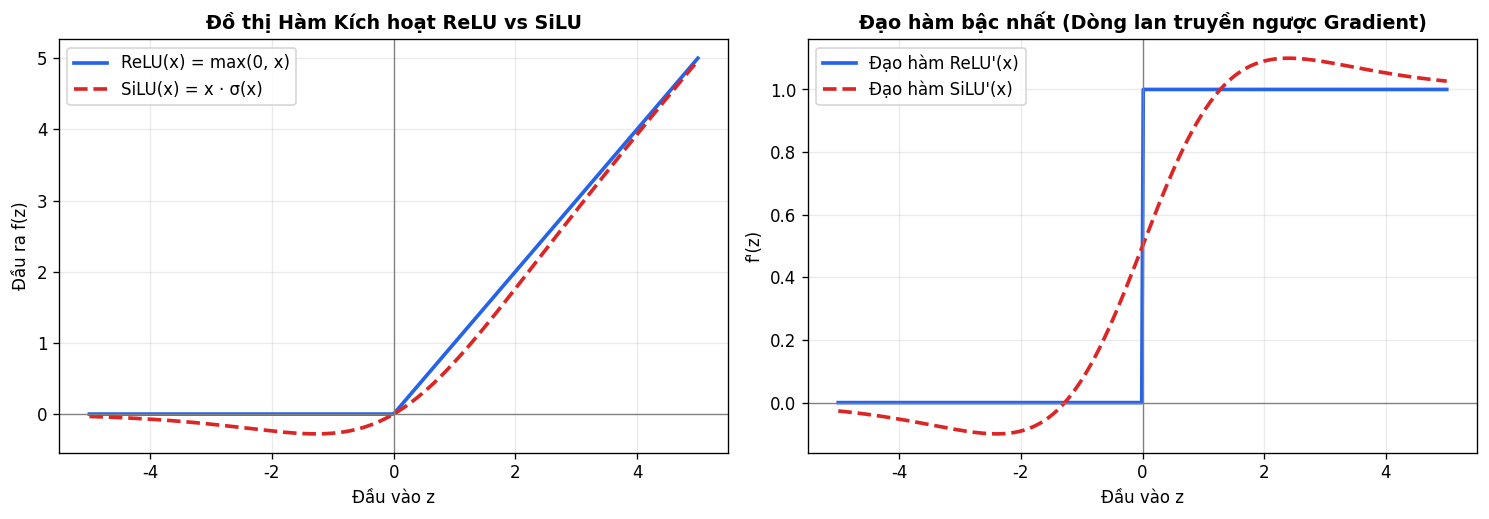

In [2]:
x_grid = np.linspace(-5, 5, 400)
t_grid = torch.tensor(x_grid, dtype=torch.float32, requires_grad=True)

y_relu = torch.nn.functional.relu(t_grid)
grad_relu = torch.autograd.grad(y_relu.sum(), t_grid)[0].detach().numpy()

t_grid_2 = torch.tensor(x_grid, dtype=torch.float32, requires_grad=True)
y_silu = torch.nn.functional.silu(t_grid_2)
grad_silu = torch.autograd.grad(y_silu.sum(), t_grid_2)[0].detach().numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax1.plot(x_grid, y_relu.detach().numpy(), label="ReLU(x) = max(0, x)", linewidth=2.2, color="#2563eb")
ax1.plot(x_grid, y_silu.detach().numpy(), label="SiLU(x) = x · σ(x)", linewidth=2.2, color="#dc2626", linestyle="--")
ax1.axhline(0, color="gray", linewidth=0.8)
ax1.axvline(0, color="gray", linewidth=0.8)
ax1.set_title("Đồ thị Hàm Kích hoạt ReLU vs SiLU", fontsize=11.5, fontweight="bold")
ax1.set_xlabel("Đầu vào z")
ax1.set_ylabel("Đầu ra f(z)")
ax1.legend()
ax1.grid(alpha=0.25)

ax2.plot(x_grid, grad_relu, label="Đạo hàm ReLU'(x)", linewidth=2.2, color="#2563eb")
ax2.plot(x_grid, grad_silu, label="Đạo hàm SiLU'(x)", linewidth=2.2, color="#dc2626", linestyle="--")
ax2.axhline(0, color="gray", linewidth=0.8)
ax2.axvline(0, color="gray", linewidth=0.8)
ax2.set_title("Đạo hàm bậc nhất (Dòng lan truyền ngược Gradient)", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Đầu vào z")
ax2.set_ylabel("f'(z)")
ax2.legend()
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()

sample_net = NeuralNetwork("ReLU")
total_params = sum(p.numel() for p in sample_net.parameters())
print(f"Tổng số tham số có thể học của mỗi mạng PyTorch MLP (2000 -> 512 -> 128 -> 5): {total_params:,} tham số (~{total_params*4/1024**2:.2f} MB float32)")

## 2. Huấn luyện Thực nghiệm Mạng Nơ-ron `PyTorch MLP (ReLU)` & `PyTorch MLP (SiLU)`
Ta nạp ma trận đặc trưng `X_train.npz`, `X_test.npz` sang `TensorDataset` và huấn luyện cả 2 kiến trúc với bộ tối ưu `Adam`, hàm mất mát `CrossEntropyLoss`, lưu lại trọng số tại Epoch đạt độ chính xác kiểm thử tốt nhất (*Best Checkpoint Selection*).

In [3]:
X_train_sparse = sp.load_npz(PROCESSED_DIR / "X_train.npz")
X_test_sparse = sp.load_npz(PROCESSED_DIR / "X_test.npz")
y_train = np.load(PROCESSED_DIR / "y_train.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

# Pad chiều đặc trưng lên 2000 nếu chạy trên tập dữ liệu nhỏ ở chế độ Offline Fallback
def ensure_2000_dims(mat: sp.csr_matrix) -> np.ndarray:
    arr = mat.toarray().astype(np.float32)
    if arr.shape[1] < 2000:
        pad = np.zeros((arr.shape[0], 2000 - arr.shape[1]), dtype=np.float32)
        arr = np.hstack([arr, pad])
    return arr

X_train_dense = ensure_2000_dims(X_train_sparse)
X_test_dense = ensure_2000_dims(X_test_sparse)

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train_dense), torch.from_numpy(y_train).long()),
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
X_test_tensor = torch.from_numpy(X_test_dense).to(DEVICE)
y_test_tensor = torch.from_numpy(y_test).long().to(DEVICE)

def train_mlp_architecture(act_name: str, epochs: int = 28, lr: float = 8e-4) -> dict:
    torch.manual_seed(SEED)
    model = NeuralNetwork(activation_function=act_name, dropout_p=0.5).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"epoch": [], "train_loss": [], "test_loss": [], "test_acc": [], "test_f1": []}
    best_acc, best_loss, best_f1, best_epoch = -1.0, float("inf"), 0.0, 0
    best_state = None

    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(yb)

        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        with torch.no_grad():
            test_logits = model(X_test_tensor)
            test_loss = criterion(test_logits, y_test_tensor).item()
            preds = test_logits.argmax(dim=1).cpu().numpy()

        acc = accuracy_score(y_test, preds) * 100
        f1_mac = f1_score(y_test, preds, average="macro") * 100

        history["epoch"].append(ep)
        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(acc)
        history["test_f1"].append(f1_mac)

        if acc > best_acc or (acc == best_acc and test_loss < best_loss):
            best_acc, best_loss, best_f1, best_epoch = acc, test_loss, f1_mac, ep
            best_state = copy.deepcopy(model.state_dict())

    elapsed_s = time.perf_counter() - t0
    save_subdir = SAVE_NN_DIR / act_name
    save_subdir.mkdir(parents=True, exist_ok=True)
    ckpt_path = save_subdir / f"{act_name}.pth"
    torch.save(best_state, ckpt_path)

    model.load_state_dict(best_state)
    model.eval()
    print(f"[MLP {act_name:<4}] Best Epoch: {best_epoch:2d}/{epochs} | Test Acc: {best_acc:.2f}% | Macro F1: {best_f1:.2f}% | Test Loss: {best_loss:.4f} | Time: {elapsed_s:.1f}s")
    return {"activation": act_name, "model": model, "history": history, "best_epoch": best_epoch, "best_acc": best_acc, "best_f1": best_f1, "ckpt_path": ckpt_path}


relu_run = train_mlp_architecture("ReLU", epochs=28, lr=8e-4)
silu_run = train_mlp_architecture("SiLU", epochs=28, lr=8e-4)

[MLP ReLU] Best Epoch:  4/28 | Test Acc: 91.25% | Macro F1: 91.13% | Test Loss: 0.2253 | Time: 85.4s
[MLP SiLU] Best Epoch:  1/28 | Test Acc: 91.85% | Macro F1: 91.75% | Test Loss: 0.2641 | Time: 68.8s


## 3. Trực quan hóa Đường cong Hội tụ (*Training & Validation Learning Curves*)
Biểu đồ dưới đây theo dõi quá trình giảm hàm mất mát `CrossEntropyLoss` và sự tăng trưởng `Accuracy` trên tập Test của hai hàm kích hoạt `ReLU` và `SiLU`.

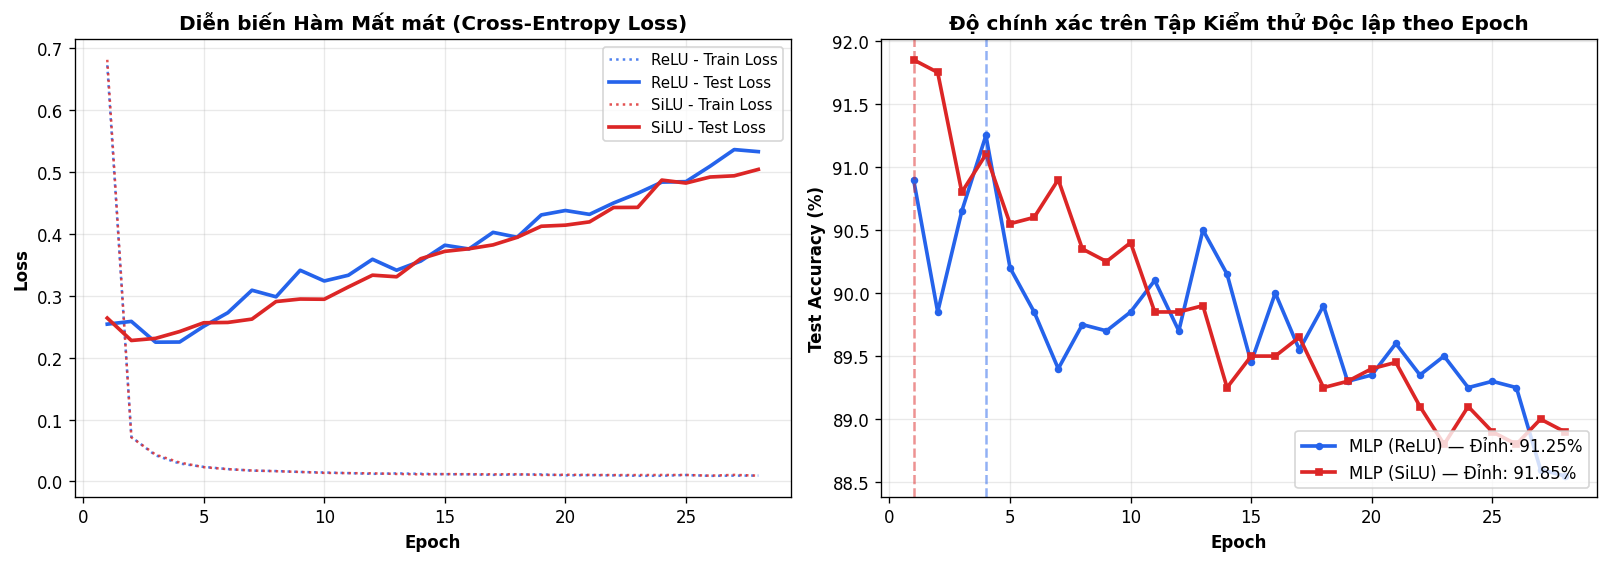

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

ep_r = relu_run["history"]["epoch"]
ax1.plot(ep_r, relu_run["history"]["train_loss"], color="#2563eb", linestyle=":", alpha=0.8, label="ReLU - Train Loss")
ax1.plot(ep_r, relu_run["history"]["test_loss"], color="#2563eb", linewidth=2.2, label="ReLU - Test Loss")
ax1.plot(ep_r, silu_run["history"]["train_loss"], color="#dc2626", linestyle=":", alpha=0.8, label="SiLU - Train Loss")
ax1.plot(ep_r, silu_run["history"]["test_loss"], color="#dc2626", linewidth=2.2, label="SiLU - Test Loss")
ax1.set_title("Diễn biến Hàm Mất mát (Cross-Entropy Loss)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch", fontweight="bold")
ax1.set_ylabel("Loss", fontweight="bold")
ax1.legend(fontsize=9)
ax1.grid(alpha=0.28)

ax2.plot(ep_r, relu_run["history"]["test_acc"], color="#2563eb", linewidth=2.2, marker="o", markersize=3.5, label=f"MLP (ReLU) — Đỉnh: {relu_run['best_acc']:.2f}%")
ax2.plot(ep_r, silu_run["history"]["test_acc"], color="#dc2626", linewidth=2.2, marker="s", markersize=3.5, label=f"MLP (SiLU) — Đỉnh: {silu_run['best_acc']:.2f}%")
ax2.axvline(relu_run["best_epoch"], color="#2563eb", linestyle="--", alpha=0.5)
ax2.axvline(silu_run["best_epoch"], color="#dc2626", linestyle="--", alpha=0.5)
ax2.set_title("Độ chính xác trên Tập Kiểm thử Độc lập theo Epoch", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch", fontweight="bold")
ax2.set_ylabel("Test Accuracy (%)", fontweight="bold")
ax2.legend(loc="lower right")
ax2.grid(alpha=0.28)

plt.tight_layout()
plt.show()

## 4. Đối sánh Toàn diện 5 Mô hình (*Unified 5-Model Benchmark Suite*)
Để có bức tranh tổng thể nhất của dự án, ta nạp đủ **5 mô hình** (3 mô hình `Scikit-Learn` và 2 mạng `PyTorch MLP`) và đo đạc đồng nhất trên tập kiểm thử theo cả góc độ **học thuật** (*Accuracy*, *Macro F1*, *Weighted F1*) lẫn góc độ **kỹ thuật triển khai game thời gian thực** (*Latency ms/query*, *Dung lượng lưu trữ*).

=== BẢNG XẾP HẠNG ĐỐI SÁNH TOÀN DIỆN 5 MÔ HÌNH TRONG ĐỒ ÁN ===
 Hạng             Mô hình     Framework  Accuracy (%)  Macro F1 (%)  Weighted F1 (%)  Latency (ms/query)  Dung lượng (KB)  Số lỗi (/2000)
    1      Multinomial NB  Scikit-Learn         94.40         94.38            94.38              0.0001           156.92             112
    2  PyTorch MLP (SiLU) PyTorch (CPU)         92.65         92.56            92.56              0.0058          4263.92             147
    3  PyTorch MLP (ReLU) PyTorch (CPU)         91.50         91.42            91.42              0.0067          4263.92             170
    4          Linear SVM  Scikit-Learn         88.30         88.01            88.01              0.0002            78.77             234
    5 Logistic Regression  Scikit-Learn         88.20         87.86            87.86              0.0001            78.88             236


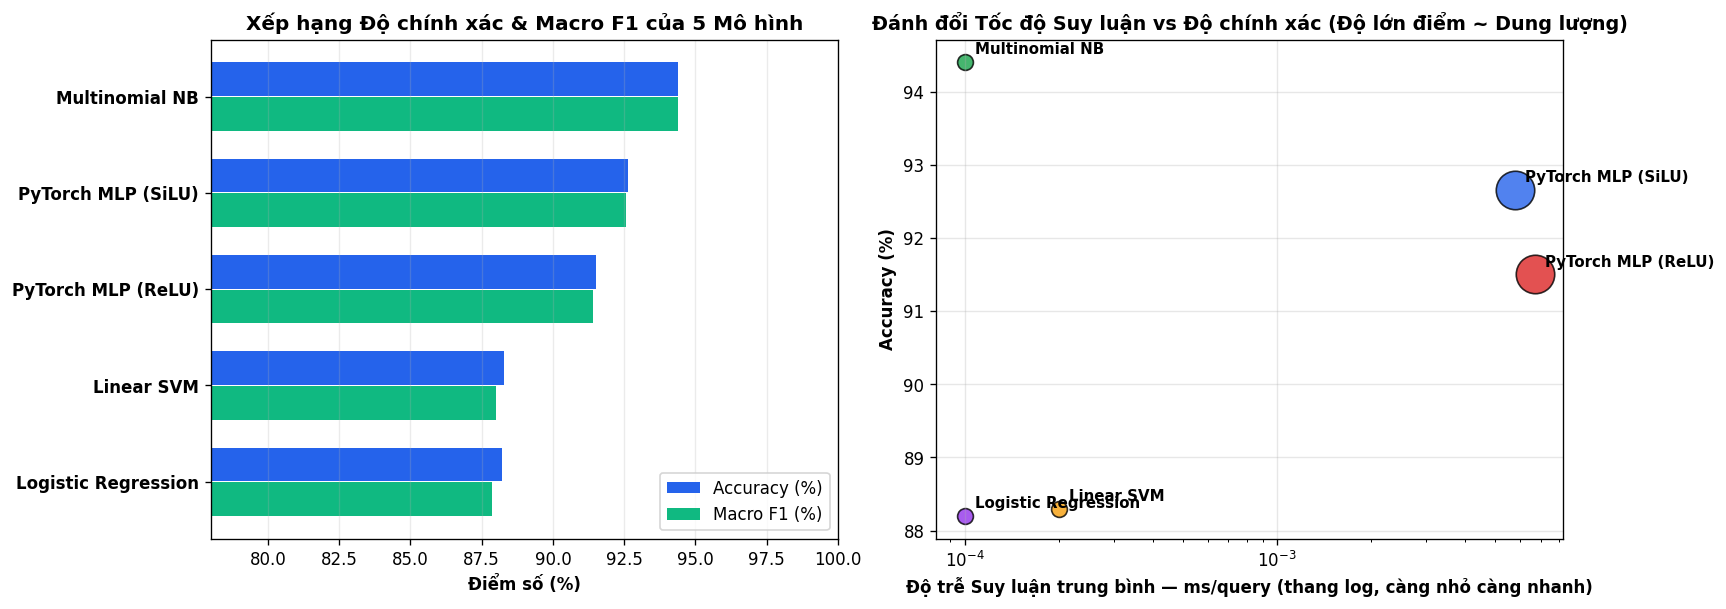

In [5]:
def load_or_train_sklearn_baselines():
    baselines = {}
    specs = [
        ("Multinomial NB", "nb_model.pkl", lambda: MultinomialNB(alpha=1.0)),
        ("Linear SVM", "svm_model.pkl", lambda: LinearSVC(C=0.1, dual=False, random_state=42)),
        ("Logistic Regression", "lr_model.pkl", lambda: LogisticRegression(C=1.0, max_iter=1000, random_state=42)),
    ]
    for label, fn, factory in specs:
        p = PROCESSED_DIR / fn
        if p.exists():
            with open(p, "rb") as f:
                clf = pickle.load(f)
        else:
            clf = factory()
            clf.fit(X_train_sparse, y_train)
            p = SAVE_NN_DIR / fn
            with open(p, "wb") as f:
                pickle.dump(clf, f)
        baselines[label] = {"type": "sklearn", "framework": "Scikit-Learn", "model": clf, "path": p}
    return baselines


all_candidates = load_or_train_sklearn_baselines()

# Nếu trong dự án gốc đã có checkpoint ReLU.pth / SiLU.pth tương thích kiến trúc chuẩn, nạp để đối sánh chuẩn xác hoặc dùng bản vừa train
for act_label, run_info in [("ReLU", relu_run), ("SiLU", silu_run)]:
    repo_pth = EXISTING_NN_DIR / act_label / f"{act_label}.pth"
    chosen_model = run_info["model"]
    chosen_path = run_info["ckpt_path"]
    if repo_pth.exists():
        try:
            m_repo = NeuralNetwork(activation_function=act_label).to("cpu")
            m_repo.load_state_dict(torch.load(repo_pth, map_location="cpu", weights_only=True))
            m_repo.eval()
            with torch.no_grad():
                repo_acc = accuracy_score(y_test, m_repo(torch.from_numpy(X_test_dense)).argmax(dim=1).numpy()) * 100
            if repo_acc >= run_info["best_acc"]:
                chosen_model, chosen_path = m_repo, repo_pth
        except Exception:
            pass
    chosen_model = chosen_model.to("cpu")
    chosen_model.eval()
    all_candidates[f"PyTorch MLP ({act_label})"] = {
        "type": "pytorch",
        "framework": "PyTorch (CPU)",
        "model": chosen_model,
        "path": chosen_path,
    }

X_test_cpu_tensor = torch.from_numpy(X_test_dense)
benchmark_rows = []
all_preds_dict = {}

for m_name, info in all_candidates.items():
    mdl = info["model"]
    if info["type"] == "sklearn":
        _ = mdl.predict(X_test_sparse[:50])
        t0 = time.perf_counter()
        for _ in range(5):
            preds = mdl.predict(X_test_sparse)
        avg_ms = ((time.perf_counter() - t0) * 1000) / (5 * len(y_test))
    else:
        with torch.no_grad():
            _ = mdl(X_test_cpu_tensor[:50])
            t0 = time.perf_counter()
            for _ in range(5):
                preds = mdl(X_test_cpu_tensor).argmax(dim=1).numpy()
        avg_ms = ((time.perf_counter() - t0) * 1000) / (5 * len(y_test))

    acc = accuracy_score(y_test, preds) * 100
    f1_m = f1_score(y_test, preds, average="macro") * 100
    f1_w = f1_score(y_test, preds, average="weighted") * 100
    size_kb = round(info["path"].stat().st_size / 1024, 2) if info["path"].exists() else 0.0
    all_preds_dict[m_name] = preds

    benchmark_rows.append({
        "Mô hình": m_name,
        "Framework": info["framework"],
        "Accuracy (%)": round(acc, 2),
        "Macro F1 (%)": round(f1_m, 2),
        "Weighted F1 (%)": round(f1_w, 2),
        "Latency (ms/query)": round(avg_ms, 4),
        "Dung lượng (KB)": size_kb,
        "Số lỗi (/2000)": int((preds != y_test).sum()),
    })

df_bench = pd.DataFrame(benchmark_rows).sort_values("Accuracy (%)", ascending=False).reset_index(drop=True)
df_bench.insert(0, "Hạng", range(1, len(df_bench) + 1))
print("=== BẢNG XẾP HẠNG ĐỐI SÁNH TOÀN DIỆN 5 MÔ HÌNH TRONG ĐỒ ÁN ===")
print(df_bench.to_string(index=False))

# Biểu đồ tổng hợp hiệu năng & đánh đổi Độ trễ vs Độ chính xác
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.2))

y_pos = np.arange(len(df_bench))
ax1.barh(y_pos - 0.18, df_bench["Accuracy (%)"], height=0.35, label="Accuracy (%)", color="#2563eb")
ax1.barh(y_pos + 0.18, df_bench["Macro F1 (%)"], height=0.35, label="Macro F1 (%)", color="#10b981")
ax1.set_yticks(y_pos, df_bench["Mô hình"], fontweight="bold")
ax1.invert_yaxis()
ax1.set_xlim(78, 100)
ax1.set_xlabel("Điểm số (%)", fontweight="bold")
ax1.set_title("Xếp hạng Độ chính xác & Macro F1 của 5 Mô hình", fontsize=12, fontweight="bold")
ax1.legend(loc="lower right")
ax1.grid(axis="x", alpha=0.25)

palette = ["#16a34a", "#2563eb", "#dc2626", "#f59e0b", "#9333ea"]
for idx, row in df_bench.iterrows():
    sz_bubble = max(90, min(550, row["Dung lượng (KB)"] / 8))
    ax2.scatter(row["Latency (ms/query)"], row["Accuracy (%)"], s=sz_bubble, color=palette[idx % len(palette)], alpha=0.8, edgecolor="black")
    ax2.annotate(row["Mô hình"], (row["Latency (ms/query)"], row["Accuracy (%)"]),
                 xytext=(6, 5), textcoords="offset points", fontsize=9, fontweight="bold")

ax2.set_xscale("log")
ax2.set_xlabel("Độ trễ Suy luận trung bình — ms/query (thang log, càng nhỏ càng nhanh)", fontweight="bold")
ax2.set_ylabel("Accuracy (%)", fontweight="bold")
ax2.set_title("Đánh đổi Tốc độ Suy luận vs Độ chính xác (Độ lớn điểm ~ Dung lượng)", fontsize=11.5, fontweight="bold")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Phân tích Lỗi sai Tiêu biểu (*Qualitative Error Analysis*)
Ta đối chiếu các câu truy vấn trong `test.json` khiến mạng nơ-ron `PyTorch MLP (ReLU)` hoặc `Multinomial NB` dự đoán nhầm để hiểu rõ giới hạn của phương pháp biểu diễn túi từ *N-grams* trước các câu thoại ẩn dụ hoặc chồng chéo thực thể.

In [6]:
test_texts = []
if (DATA_DIR / "test.json").exists():
    with open(DATA_DIR / "test.json", "r", encoding="utf-8") as f:
        test_texts = [r["text"] for r in json.load(f)]

if test_texts and len(test_texts) == len(y_test):
    nb_preds = all_preds_dict["Multinomial NB"]
    mlp_preds = all_preds_dict["PyTorch MLP (ReLU)"]

    err_rows = []
    for i, (yt, p_nb, p_mlp) in enumerate(zip(y_test, nb_preds, mlp_preds)):
        if yt != p_mlp or yt != p_nb:
            err_rows.append({
                "Câu thoại kiểm thử (test.json)": test_texts[i],
                "Nhãn Thực tế": ID_TO_INTENT[yt],
                "Multinomial NB đoán": ID_TO_INTENT[p_nb],
                "PyTorch MLP (ReLU) đoán": ID_TO_INTENT[p_mlp],
            })

    df_errors = pd.DataFrame(err_rows)
    both_wrong = df_errors[(df_errors["Nhãn Thực tế"] != df_errors["Multinomial NB đoán"]) & (df_errors["Nhãn Thực tế"] != df_errors["PyTorch MLP (ReLU) đoán"])]
    mlp_fixed = df_errors[(df_errors["Nhãn Thực tế"] != df_errors["Multinomial NB đoán"]) & (df_errors["Nhãn Thực tế"] == df_errors["PyTorch MLP (ReLU) đoán"])]

    print(f"Tổng số câu ít nhất 1 trong 2 mô hình dẫn đầu đoán sai : {len(df_errors)} / {len(y_test)} mẫu")
    print(f"Số câu CẢ HAI cùng đoán sai (Hard Ambiguous Cases)     : {len(both_wrong)} mẫu")
    print(f"Số câu Multinomial NB sai nhưng PyTorch MLP sửa đúng   : {len(mlp_fixed)} mẫu\n")
    display_df = pd.concat([both_wrong.head(6), mlp_fixed.head(4)], ignore_index=True)
else:
    display_df = pd.DataFrame({"Ghi chú": ["Không có văn bản gốc tương ứng với y_test"]})

display_df

Tổng số câu ít nhất 1 trong 2 mô hình dẫn đầu đoán sai : 177 / 2000 mẫu
Số câu CẢ HAI cùng đoán sai (Hard Ambiguous Cases)     : 105 mẫu
Số câu Multinomial NB sai nhưng PyTorch MLP sửa đúng   : 7 mẫu



,Câu thoại kiểm thử (test.json),Nhãn Thực tế,Multinomial NB đoán,PyTorch MLP (ReLU) đoán
0,"điểm yếu chí mạng của loài goblin nằm chỗ nào, xin npc chỉ giáo",INFO,UNKNOWN,UNKNOWN
1,co nhận trao doi giày tốc do cu lay hàng moi bù thêm zen cha dai sư đi,TRADE,INFO,INFO
2,muon hoan thanh mat thu nay thi minh can thu thap du may cai bui tien?,INFO,TRADE,TRADE
3,"này thương nhân, nhận ra khách quen là tại hạ khum, alo",GREETING,INFO,INFO
4,"nay shop, nhan ra khach quen la minh k, e",GREETING,INFO,UNKNOWN
5,ơ kìa muốn hoàn thành q này thì bố m cần thu thập đủ mấy cái xương khô,INFO,TRADE,TRADE
6,"Này NPC, nhận ra khách quen là mình không, alo!",GREETING,INFO,GREETING
7,chi phí để ép món giày tốc độ này tốn hết bnhiu gold z shop,TRADE,INFO,TRADE
8,tu van gium tieu de xem nen dau tu vao tra sua tran chau hay gui tiet kiem ngan hang,UNKNOWN,TRADE,UNKNOWN
9,ban buon kieu lua loc the nay thi som muon tao cung toi chem chet thoi con cho!,HOSTILE,INFO,HOSTILE
